# Project: Transfer Learning 
### Soren Patel

**AI Usage:** I used AI for markdown formatting, 

Pretrained **ResNet18** with a frozen feature extractor and a new trainable head, trained on images scraped from Bing.

**Expected layout** (current directory):
- `train/{boats,cars,planes,trains}/...`
- `test/{boats,cars,planes,trains}/...`

**Sections**
1. Setup
2. Data exploration
3. Transforms and dataset builder
4. Model (ResNet18 + new head)
5. Helper functions (train, evaluate, plot)
6. Baseline (the given code, 20 epochs) + confusion matrix, mistakes, feature embeddings
7. Q1: more classes; which classes are hard?
8. Q2: depth, width, dropout, activations, fine-tuning
9. Q3: learning rate
10. Q4: augmentation, overfitting, normalization
11. Q5: early stopping
12. Extra: how much data do we need?
13. Final model

Experiments use `EXP_EPOCHS` (default 10) to keep runtimes manageable.

## 1. Setup

In [1]:
import os, time, copy, random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import torchinfo

from PIL import Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# let's do insecure things to access the internet, because ITSD has a MITM attack
import ssl
_create_unverified_https_context = ssl._create_unverified_context
ssl._create_default_https_context = _create_unverified_https_context

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", device, "|", torch.cuda.get_device_name(0) if device == 'cuda' else "NO GPU - training will be slow")

SEED = 470
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

device: cpu | NO GPU - training will be slow


In [2]:
# ---- config ----
train_data_path = 'train'
test_data_path  = 'test'
ALL_CLASSES = sorted(d for d in os.listdir(train_data_path)
                     if os.path.isdir(os.path.join(train_data_path, d)))   # auto-detect class folders
EXP_EPOCHS  = 10     # epochs per experiment run (baseline uses 20, like the given code)
BATCH_SIZE  = 32
NUM_WORKERS = 4      # set to 0 if the DataLoader hangs/crashes in Jupyter
print("classes:", ALL_CLASSES)

classes: ['boats', 'cars', 'planes', 'trains']


## 2. Data exploration
Check class balance, look at the images, check image sizes, and find corrupt files before training.

,train,test,total,test_frac
boats,265,89,354,0.251
cars,285,96,381,0.252
planes,123,42,165,0.255
trains,327,110,437,0.252


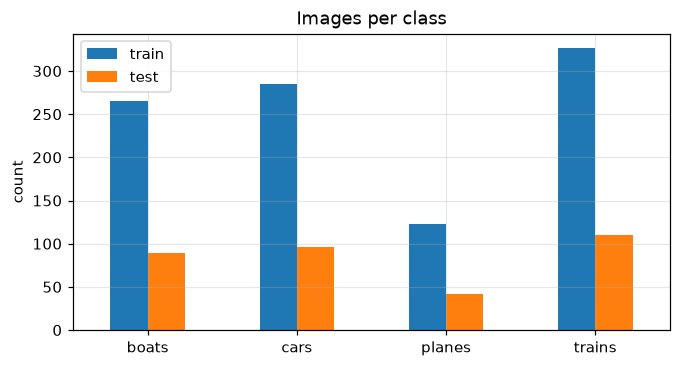

In [3]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp')
def list_images(split, cls):
    d = os.path.join(split, cls)
    return [os.path.join(d, f) for f in os.listdir(d) if f.lower().endswith(IMG_EXT)]

counts = pd.DataFrame({s: {c: len(list_images(s, c)) for c in ALL_CLASSES} for s in ['train', 'test']})
counts['total'] = counts.sum(axis=1)
counts['test_frac'] = (counts['test'] / counts['total']).round(3)
display(counts)

ax = counts[['train', 'test']].plot.bar(figsize=(7, 3.5), rot=0)
ax.set_title("Images per class"); ax.set_ylabel("count")
plt.show()

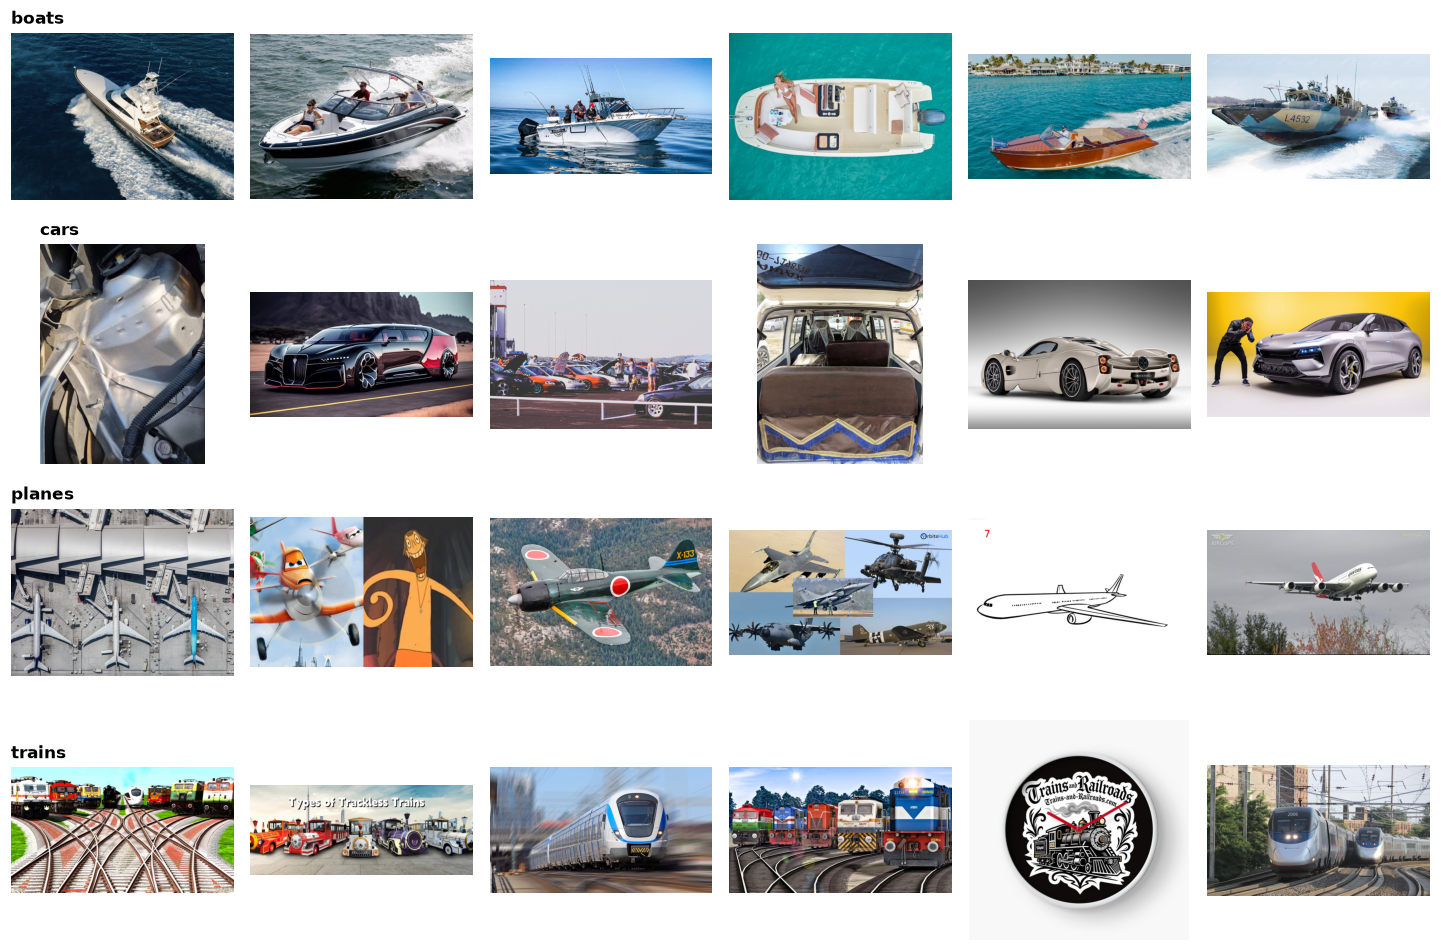

In [4]:
# random samples from each class
n = 6
fig, axes = plt.subplots(len(ALL_CLASSES), n, figsize=(2.2 * n, 2.2 * len(ALL_CLASSES)))
for i, c in enumerate(ALL_CLASSES):
    paths = random.sample(list_images('train', c), n)
    for j, p in enumerate(paths):
        axes[i, j].imshow(Image.open(p).convert('RGB'))
        axes[i, j].axis('off')
        if j == 0: axes[i, j].set_title(c, loc='left', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

corrupt/unreadable files: 0


cls            boats    cars  planes  trains
w      count   354.0   381.0   165.0   437.0
       mean   1646.7  1523.7  1741.6  1379.2
       std    1093.4   852.4  1111.9   669.3
       min     236.0   372.0   471.0   239.0
       25%    1000.0   940.0  1024.0  1000.0
       50%    1280.0  1280.0  1344.0  1280.0
       75%    1973.8  1920.0  2000.0  1600.0
       max    6933.0  5760.0  6666.0  4820.0
h      count   354.0   381.0   165.0   437.0
       mean   1187.7  1019.0  1276.5   932.1
       std     806.4   510.4   869.6   478.0
       min     134.0   250.0   237.0   249.0
       25%     640.8   675.0   720.0   667.0
       50%     937.0   964.0  1080.0   750.0
       75%    1433.5  1080.0  1464.0  1080.0
       max    5184.0  3840.0  4716.0  3543.0
aspect count   354.0   381.0   165.0   437.0
       mean      1.5     1.5     1.5     1.5
       std       0.5     0.4     0.4     0.4
       min       0.2     0.4     0.6     0.6
       25%       1.3     1.4     1.2     1.4
       50%       1.5     1.8     1.5     1.6
       75%       1.8     1.8     1.8     1.8
       max       6.3     3.5     3.2     3.1

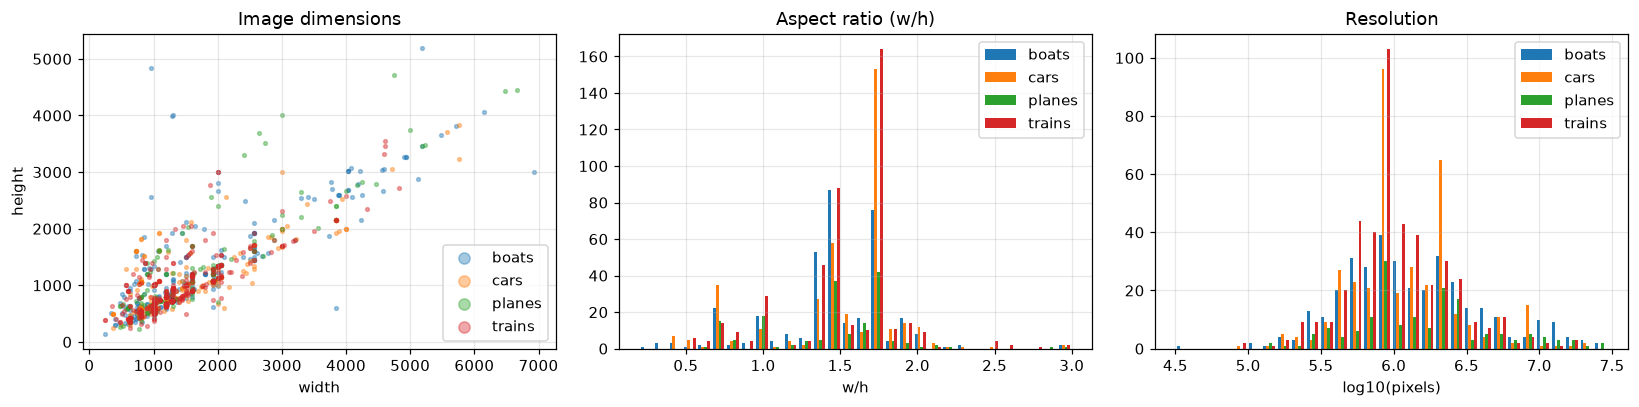

In [5]:
# corrupt-file check + image size / aspect-ratio distribution
bad, rows = [], []
for s in ['train', 'test']:
    for c in ALL_CLASSES:
        for p in list_images(s, c):
            try:
                with Image.open(p) as im:
                    im.verify()
                with Image.open(p) as im:
                    w, h = im.size
                rows.append(dict(split=s, cls=c, w=w, h=h, path=p))
            except Exception as e:
                bad.append(p)
sizes = pd.DataFrame(rows)
sizes['aspect'] = sizes.w / sizes.h
print(f"corrupt/unreadable files: {len(bad)}")
for p in bad[:20]: print("  ", p)
display(sizes.groupby('cls')[['w', 'h', 'aspect']].describe().round(1).T)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for c in ALL_CLASSES:
    d = sizes[sizes.cls == c]
    ax[0].scatter(d.w, d.h, s=6, alpha=0.4, label=c)
ax[0].set(title="Image dimensions", xlabel="width", ylabel="height"); ax[0].legend(markerscale=3)
ax[1].hist([sizes[sizes.cls == c].aspect.clip(0, 3) for c in ALL_CLASSES], bins=30, label=ALL_CLASSES)
ax[1].set(title="Aspect ratio (w/h)", xlabel="w/h"); ax[1].legend()
ax[2].hist([np.log10(sizes[sizes.cls == c].w * sizes[sizes.cls == c].h) for c in ALL_CLASSES], bins=30, label=ALL_CLASSES)
ax[2].set(title="Resolution", xlabel="log10(pixels)"); ax[2].legend()
plt.tight_layout(); plt.show()

In [6]:
# near-duplicate check (Bing often returns the same image under different URLs): same file size + dimensions
sizes['bytes'] = sizes.path.map(os.path.getsize)
dups = sizes[sizes.duplicated(['bytes', 'w', 'h'], keep=False)].sort_values('bytes')
print(f"{len(dups)} files share (bytes, width, height) with another file")
# duplicates that cross train/test would leak test data into training
leak = dups.groupby(['bytes', 'w', 'h']).split.nunique()
print("duplicate groups spanning both train and test (leakage):", int((leak > 1).sum()))

5 files share (bytes, width, height) with another file
duplicate groups spanning both train and test (leakage): 1


**Things to note from this section**

## 3. Transforms and datasets
Random augmentations on training images only. Test images are only resized and converted to tensors. (The given code does *not* normalize with ImageNet statistics; we test that in Section 10.)

In [7]:
#transformations for training data
random_transform = transforms.Compose([
    transforms.RandomResizedCrop(256),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.ToTensor()
])

#transformations for testing data
common_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

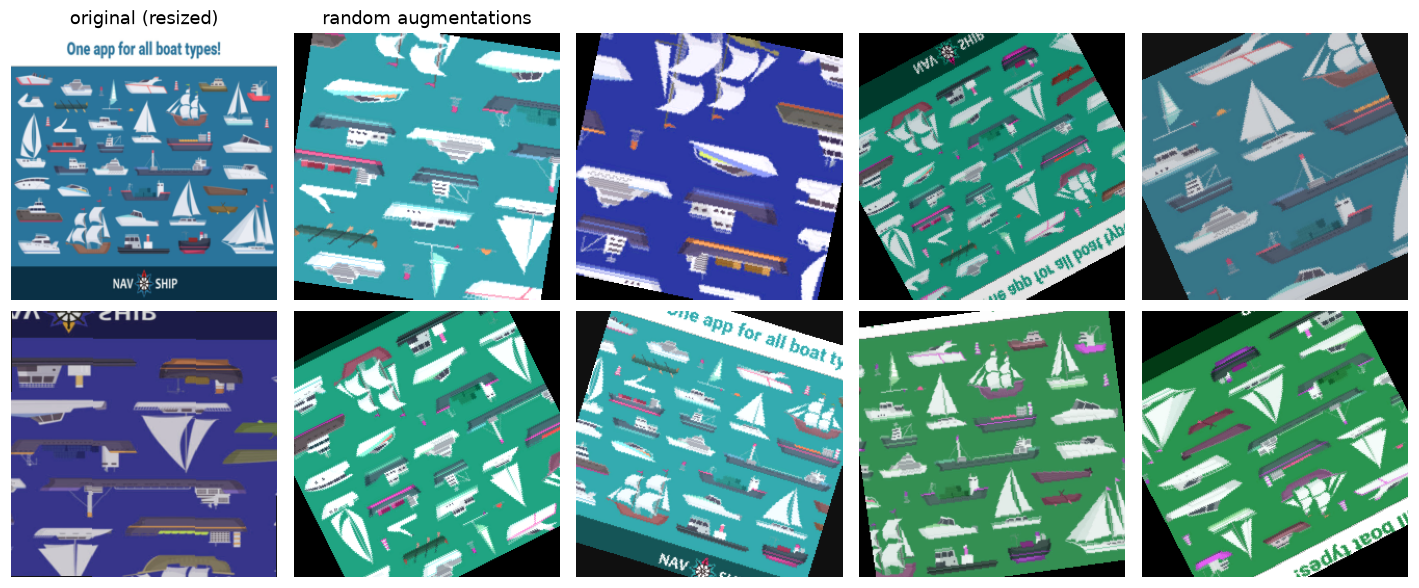

In [8]:
# preview: the same image under 9 random augmentations
p = random.choice(list_images('train', ALL_CLASSES[0]))
img = Image.open(p).convert('RGB')
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
axes[0, 0].imshow(common_transform(img).permute(1, 2, 0)); axes[0, 0].set_title("original (resized)")
for a in axes.flat[1:]:
    a.imshow(random_transform(img).permute(1, 2, 0).clamp(0, 1))
for a in axes.flat: a.axis('off')
axes.flat[1].set_title("random augmentations")
plt.tight_layout(); plt.show()

### Dataset builder
The given code builds loaders directly from `ImageFolder`. `make_loaders` wraps that so experiments can (a) use a subset of the classes, (b) swap transforms, (c) use a fraction of the training data, and (d) carve a **validation split** out of `train/`. The validation set drives early stopping and model selection; the `test/` set is only for reporting.

In [9]:
def filter_classes(ds, classes):
    """Restrict an ImageFolder to `classes` and remap labels to 0..k-1."""
    keep = {ds.class_to_idx[c]: i for i, c in enumerate(classes)}
    ds.samples = [(p, keep[t]) for p, t in ds.samples if t in keep]
    ds.imgs = ds.samples
    ds.targets = [t for _, t in ds.samples]
    ds.classes = list(classes)
    ds.class_to_idx = {c: i for i, c in enumerate(classes)}
    return ds

def make_loaders(classes=None, train_tf=None, test_tf=None, val_frac=0.15, train_frac=1.0,
                 batch_size=BATCH_SIZE, num_workers=NUM_WORKERS):
    classes = list(classes) if classes is not None else ALL_CLASSES
    train_tf = random_transform if train_tf is None else train_tf
    test_tf  = common_transform if test_tf is None else test_tf

    tr_full  = filter_classes(datasets.ImageFolder(train_data_path, transform=train_tf), classes)
    val_full = filter_classes(datasets.ImageFolder(train_data_path, transform=test_tf), classes)  # same files, no augmentation
    test_ds  = filter_classes(datasets.ImageFolder(test_data_path,  transform=test_tf), classes)

    idx = np.random.RandomState(SEED).permutation(len(tr_full))
    n_val = int(val_frac * len(idx))
    val_idx, tr_idx = idx[:n_val], idx[n_val:]
    tr_idx = tr_idx[:max(1, int(len(tr_idx) * train_frac))]

    mk = lambda ds, shuffle: DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)
    return dict(train=mk(Subset(tr_full, tr_idx), True), val=mk(Subset(val_full, val_idx), False),
                test=mk(test_ds, False), classes=classes, test_ds=test_ds,
                sizes=(len(tr_idx), len(val_idx), len(test_ds)))

L = make_loaders()
print("classes:", L['classes'], "| train/val/test sizes:", L['sizes'])

classes: ['boats', 'cars', 'planes', 'trains'] | train/val/test sizes: (850, 150, 336)


## 4. The model
ResNet18 with ImageNet weights, ~11M parameters. Freeze every pretrained parameter, then replace `model.fc` with a new randomly-initialized layer. Only that layer trains.

In [10]:
def build_model(arch='resnet18', n_classes=4, hidden=0, dropout=0.0, act=nn.ReLU, unfreeze=()):
    """Pretrained backbone (frozen) + new head.
    hidden=0 -> single Linear(512 -> n_classes), exactly the given code.
    unfreeze -> names of backbone blocks to fine-tune too, e.g. ('layer4',)."""
    model = torchvision.models.get_model(arch, weights='DEFAULT')
    for p in model.parameters():
        p.requires_grad = False                      # frozen feature extractor
    in_f = model.fc.in_features
    layers, d = [], in_f
    if hidden:
        if dropout: layers.append(nn.Dropout(dropout))
        layers += [nn.Linear(in_f, hidden), act()]
        d = hidden
    if dropout: layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(d, n_classes))
    model.fc = layers[0] if len(layers) == 1 else nn.Sequential(*layers)   # new head is trainable
    for name in unfreeze:
        for p in getattr(model, name).parameters():
            p.requires_grad = True
    return model.to(device)

# look at the pretrained network: what's its final output size? Why?
pretrained = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
print(pretrained)
print("\nOriginal fc:", pretrained.fc)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

**Final output size:** the original `fc` is `Linear(512 -> 1000)` because ResNet18 was trained on ImageNet, which has 1000 classes (one logit per class). The 512 is the channel count of the last conv stage after global average pooling. We replace it with `Linear(512 -> n_classes)` so the output matches our task.

In [11]:
model = build_model(n_classes=len(ALL_CLASSES))
torchinfo.summary(model, input_size=(1, 3, 256, 256), depth=2,
                  col_names=("output_size", "num_params", "trainable"))

Layer (type:depth-idx)                   Output Shape              Param #                   Trainable
ResNet                                   [1, 4]                    --                        Partial
├─Conv2d: 1-1                            [1, 64, 128, 128]         (9,408)                   False
├─BatchNorm2d: 1-2                       [1, 64, 128, 128]         (128)                     False
├─ReLU: 1-3                              [1, 64, 128, 128]         --                        --
├─MaxPool2d: 1-4                         [1, 64, 64, 64]           --                        --
├─Sequential: 1-5                        [1, 64, 64, 64]           --                        False
│    └─BasicBlock: 2-1                   [1, 64, 64, 64]           (73,984)                  False
│    └─BasicBlock: 2-2                   [1, 64, 64, 64]           (73,984)                  False
├─Sequential: 1-6                        [1, 128, 32, 32]          --                        False
│    └─Bas

## 5. Helper functions
Training loop (same Adam + CrossEntropyLoss as the given code), evaluation, early stopping, plotting, and a one-call `run()` for experiments.

- Frozen backbone layers stay in `eval()` mode during training so the pretrained BatchNorm statistics aren't disturbed.
- Test accuracy is recorded every epoch **for plotting only**. Early stopping and "best epoch" use the validation split.

In [12]:
def set_train_mode(model):
    """train mode, except frozen blocks stay in eval (keeps pretrained BatchNorm stats fixed)."""
    model.train()
    for m in model.children():
        params = list(m.parameters())
        if params and not any(p.requires_grad for p in params):
            m.eval()

@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    loss_sum, n, preds, targets, probs = 0.0, 0, [], [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        if criterion is not None:
            loss_sum += criterion(out, y).item() * len(y)
        pr = out.softmax(1)
        preds.append(pr.argmax(1).cpu()); targets.append(y.cpu()); probs.append(pr.cpu())
        n += len(y)
    preds, targets, probs = torch.cat(preds).numpy(), torch.cat(targets).numpy(), torch.cat(probs).numpy()
    return dict(loss=loss_sum / n, acc=(preds == targets).mean(), preds=preds, targets=targets, probs=probs)

def train_model(model, L, epochs=20, lr=1e-3, patience=None, verbose=True, label=''):
    criterion = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(params, lr=lr)
    h = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'test_loss', 'test_acc', 'epoch_time']}
    h['trainable'] = sum(p.numel() for p in params)
    best, best_ep, best_state, bad, t0 = float('inf'), 1, None, 0, time.time()

    for ep in range(1, epochs + 1):
        te = time.time()
        set_train_mode(model)
        loss_sum, correct, n = 0.0, 0, 0
        for data, target in L['train']:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(target); n += len(target)
            correct += (output.argmax(1) == target).sum().item()
        v, t = evaluate(model, L['val'], criterion), evaluate(model, L['test'], criterion)
        for k, val in [('train_loss', loss_sum / n), ('train_acc', correct / n), ('val_loss', v['loss']),
                       ('val_acc', v['acc']), ('test_loss', t['loss']), ('test_acc', t['acc']),
                       ('epoch_time', time.time() - te)]:
            h[k].append(val)
        if verbose:
            print(f"[{label}] epoch {ep:2d} | train {h['train_loss'][-1]:.3f}/{h['train_acc'][-1]:.3f} "
                  f"| val {v['loss']:.3f}/{v['acc']:.3f} | test acc {t['acc']:.3f}")
        if v['loss'] < best - 1e-4:
            best, best_ep, bad = v['loss'], ep, 0
            if patience: best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience and bad >= patience:
                if verbose: print(f"[{label}] early stop at epoch {ep} (best epoch {best_ep})")
                break
    if patience and best_state is not None:
        model.load_state_dict(best_state)         # restore best weights
    h['best_epoch'], h['time'] = best_ep, time.time() - t0
    h['stopped_early'] = len(h['val_loss']) < epochs
    if not verbose:
        print(f"[{label}] done in {h['time']:.0f}s | best epoch {best_ep} | test acc @best-val {h['test_acc'][best_ep-1]:.3f}")
    return h

def run(label, classes=None, train_tf=None, test_tf=None, epochs=None, lr=1e-3, train_frac=1.0,
        patience=None, arch='resnet18', verbose=False, **model_kw):
    """Build loaders + model, train, return (model, history, loaders)."""
    seed_everything()
    Lr = make_loaders(classes, train_tf, test_tf, train_frac=train_frac)
    m = build_model(arch, len(Lr['classes']), **model_kw)
    h = train_model(m, Lr, epochs or EXP_EPOCHS, lr, patience, verbose, label)
    return m, h, Lr

In [13]:
def plot_history(h, title=''):
    ep = np.arange(1, len(h['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for k, c in [('train', 'C0'), ('val', 'C1'), ('test', 'C2')]:
        ax[0].plot(ep, h[f'{k}_loss'], label=k, color=c, marker='o', ms=3)
        ax[1].plot(ep, h[f'{k}_acc'],  label=k, color=c, marker='o', ms=3)
    for a, name in zip(ax, ['Loss', 'Accuracy']):
        a.axvline(h['best_epoch'], color='gray', ls='--', lw=1, label=f"best val epoch ({h['best_epoch']})")
        a.set(title=f"{title} {name}", xlabel='epoch'); a.legend()
    plt.tight_layout(); plt.show()

def compare(results, metrics=('train_loss', 'val_acc', 'test_acc'), title=''):
    """Overlay several runs. results: {label: history}"""
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4))
    for ax, m in zip(np.atleast_1d(axes), metrics):
        for lab, h in results.items():
            ax.plot(range(1, len(h[m]) + 1), h[m], marker='o', ms=3, label=str(lab))
        ax.set(title=f"{title} {m}", xlabel='epoch'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

def summarize(results):
    rows = []
    for lab, h in results.items():
        b = h['best_epoch'] - 1
        conv = next((i + 1 for i, a in enumerate(h['val_acc']) if a >= max(h['val_acc']) - 0.01), len(h['val_acc']))
        rows.append({'run': lab, 'trainable_params': h['trainable'], 'epochs_run': len(h['val_acc']),
                     'best_epoch': h['best_epoch'], 'epochs_to_converge': conv,
                     'train_acc(last)': h['train_acc'][-1], 'val_acc(best)': max(h['val_acc']),
                     'test_acc(last)': h['test_acc'][-1], 'test_acc@best_val': h['test_acc'][b],
                     'train-test gap': h['train_acc'][-1] - h['test_acc'][-1],
                     'sec/epoch': np.mean(h['epoch_time']), 'total_sec': h['time']})
    return pd.DataFrame(rows).set_index('run').round(4)

def report(model, Lr, title=''):
    """Confusion matrices + per-class metrics on the test set."""
    r = evaluate(model, Lr['test'])
    cls = Lr['classes']
    cm = confusion_matrix(r['targets'], r['preds'])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=cls).plot(ax=ax[0], cmap='Blues', colorbar=False)
    ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=cls).plot(
        ax=ax[1], cmap='Blues', colorbar=False, values_format='.2f')
    ax[0].set_title(f"{title} confusion (counts)"); ax[1].set_title("row-normalized (recall)")
    for a in ax: a.grid(False)
    plt.tight_layout(); plt.show()
    print(classification_report(r['targets'], r['preds'], target_names=cls, digits=3))
    return r

def show_mistakes(r, Lr, n=8):
    """Most confidently wrong test images."""
    paths = [p for p, _ in Lr['test_ds'].samples]
    wrong = np.where(r['preds'] != r['targets'])[0]
    if len(wrong) == 0:
        print("No mistakes!"); return
    wrong = wrong[np.argsort(-r['probs'][wrong].max(1))][:n]
    cols = min(4, len(wrong)); rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows))
    for a in np.atleast_1d(axes).flat: a.axis('off')
    for a, i in zip(np.atleast_1d(axes).flat, wrong):
        a.imshow(Image.open(paths[i]).convert('RGB'))
        a.set_title(f"true: {Lr['classes'][r['targets'][i]]}\npred: {Lr['classes'][r['preds'][i]]} ({r['probs'][i].max():.2f})",
                    fontsize=9, color='firebrick')
    plt.suptitle("Most confident mistakes"); plt.tight_layout(); plt.show()

## 6. Baseline: the given code
ResNet18, frozen backbone, single `Linear(512 -> k)` head, Adam lr=1e-3, the given augmentations, 20 epochs.

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[baseline] epoch  1 | train 1.285/0.396 | val 1.038/0.600 | test acc 0.637


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[baseline] epoch  2 | train 1.058/0.558 | val 0.780/0.707 | test acc 0.759


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

...

[baseline] epoch 18 | train 0.631/0.764 | val 0.380/0.867 | test acc 0.893


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[baseline] epoch 19 | train 0.644/0.754 | val 0.382/0.873 | test acc 0.893


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[baseline] epoch 20 | train 0.615/0.766 | val 0.418/0.847 | test acc 0.887


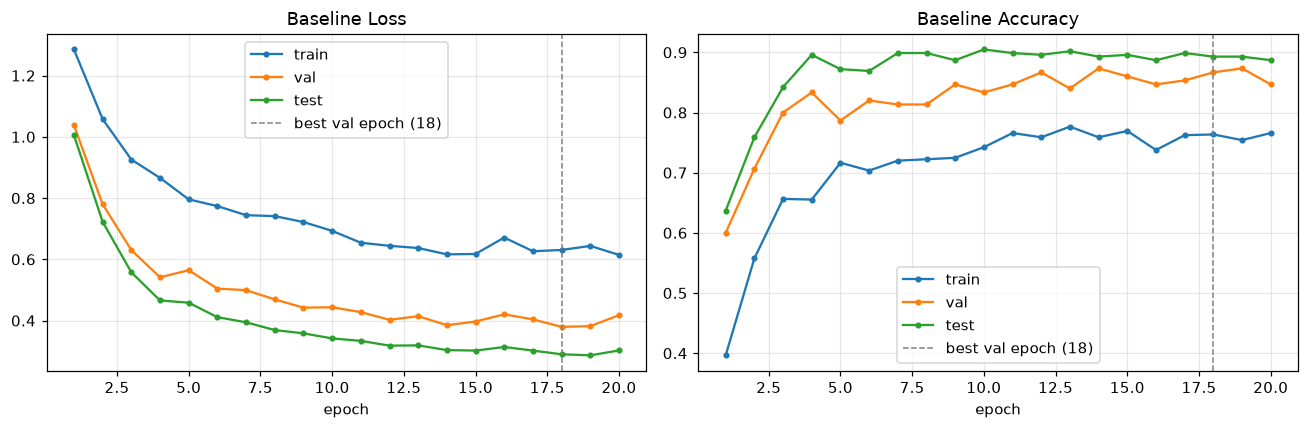

Test Accuracy (final epoch): 88.69%


In [14]:
import warnings

# Mute only the Pillow palette transparency warning
warnings.filterwarnings(
    "ignore", 
    category=UserWarning, 
    message=r".*Palette images with Transparency.*"
)

base_model, base_h, base_L = run('baseline', epochs=20, verbose=True)
plot_history(base_h, 'Baseline')
print(f"Test Accuracy (final epoch): {base_h['test_acc'][-1] * 100:.2f}%")

### Confusion matrix, per-class metrics, mistakes

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


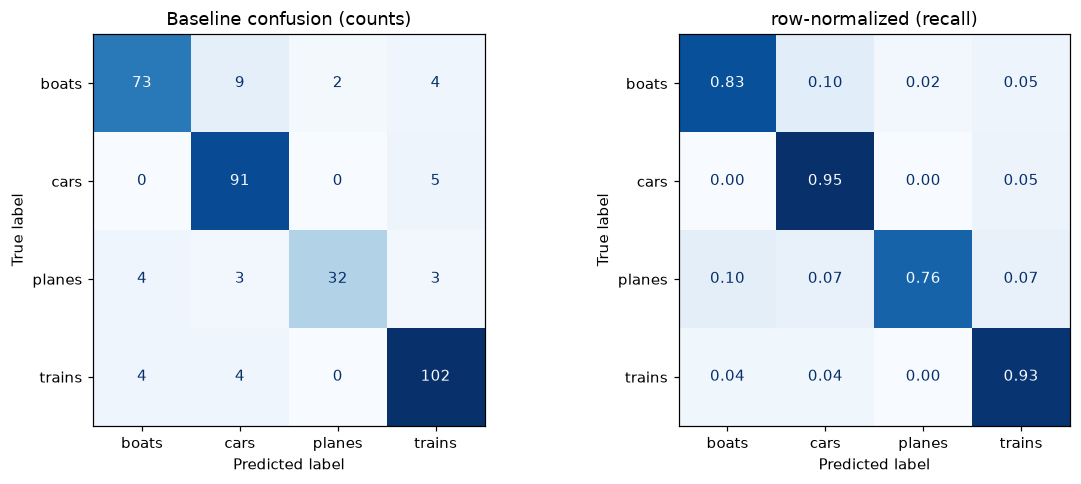

              precision    recall  f1-score   support

       boats      0.901     0.830     0.864        88
        cars      0.850     0.948     0.897        96
      planes      0.941     0.762     0.842        42
      trains      0.895     0.927     0.911       110

    accuracy                          0.887       336
   macro avg      0.897     0.867     0.878       336
weighted avg      0.890     0.887     0.886       336



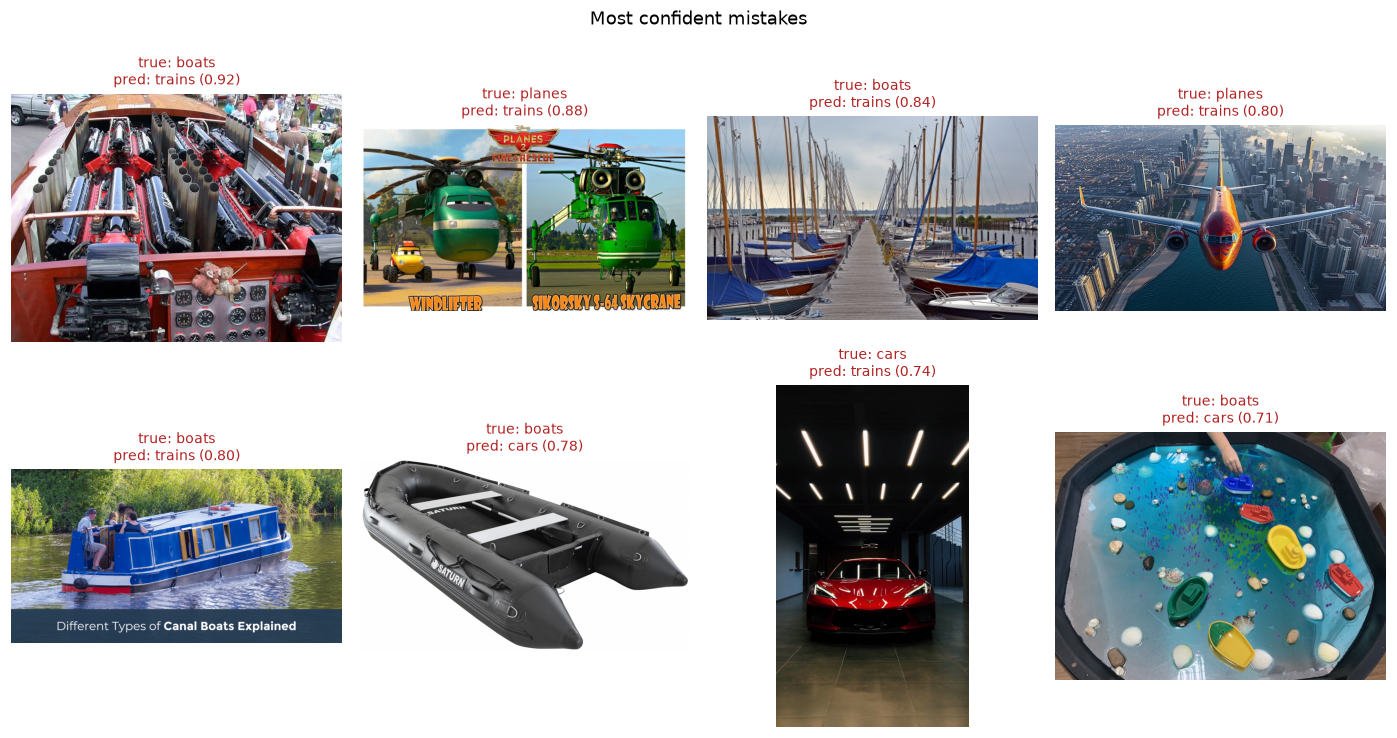

In [15]:
r = report(base_model, base_L, 'Baseline')
show_mistakes(r, base_L)

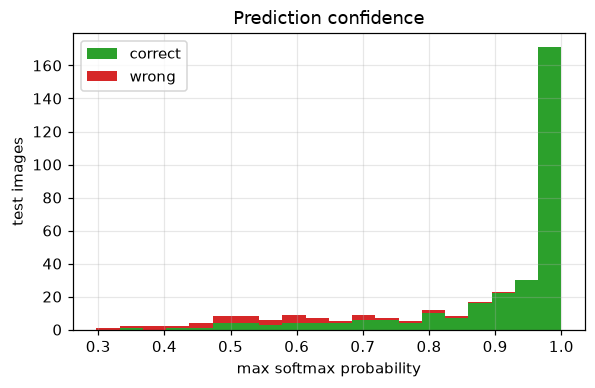

In [16]:
# how confident is the model when it's right vs wrong?
conf = r['probs'].max(1); ok = r['preds'] == r['targets']
plt.figure(figsize=(6, 3.5))
plt.hist([conf[ok], conf[~ok]], bins=20, label=['correct', 'wrong'], stacked=True, color=['C2', 'C3'])
plt.xlabel("max softmax probability"); plt.ylabel("test images"); plt.title("Prediction confidence"); plt.legend(); plt.show()

### What do the frozen features look like?
Take the 512-d features from the pretrained backbone (before the new head), project to 2D with PCA and t-SNE. Clean clusters mean a linear head will do well; overlapping clusters predict confusion.

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


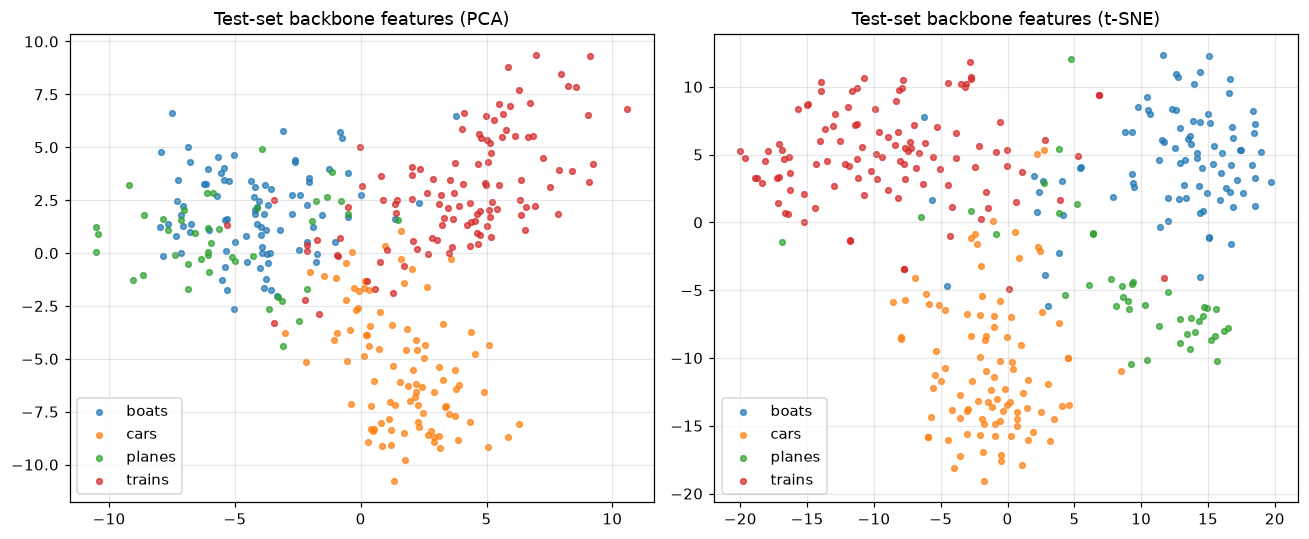

In [17]:
@torch.no_grad()
def extract_features(model, loader):
    fe = copy.deepcopy(model); fe.fc = nn.Identity(); fe.eval()
    F, Y = [], []
    for x, y in loader:
        F.append(fe(x.to(device)).cpu()); Y.append(y)
    return torch.cat(F).numpy(), torch.cat(Y).numpy()

feats, ys = extract_features(base_model, base_L['test'])
pca2 = PCA(2, random_state=SEED).fit_transform(feats)
tsne2 = TSNE(2, perplexity=min(30, len(feats) - 1), init='pca', random_state=SEED).fit_transform(feats)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, emb, name in zip(ax, [pca2, tsne2], ['PCA', 't-SNE']):
    for i, c in enumerate(base_L['classes']):
        a.scatter(*emb[ys == i].T, s=14, alpha=0.7, label=c)
    a.set_title(f"Test-set backbone features ({name})"); a.legend()
plt.tight_layout(); plt.show()

## 7. Q1: How does adding more classes affect performance? Which classes are hard to tell apart?

**(a)** Train with the first 2, 3, then all classes. **(b)** Train a binary classifier for every pair to find the hardest pairs.

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[2 classes] done in 199s | best epoch 10 | test acc @best-val 0.946


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[3 classes] done in 220s | best epoch 10 | test acc @best-val 0.907


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[4 classes] done in 254s | best epoch 9 | test acc @best-val 0.887


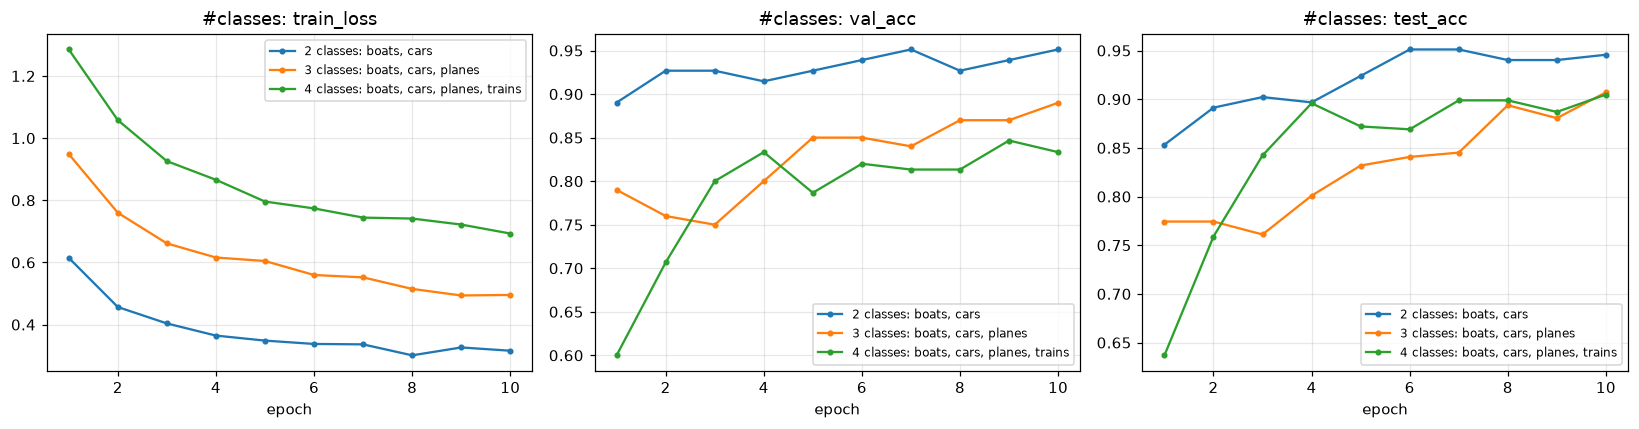

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
"2 classes: boats, cars",1026,10,10,7,0.8782,0.9512,0.9457,0.9457,-0.0674,19.9269,199.2692
"3 classes: boats, cars, planes",1539,10,10,10,0.8010,0.8900,0.9071,0.9071,-0.1060,22.0187,220.1871
"4 classes: boats, cars, planes, trains",2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,25.4074,254.0740


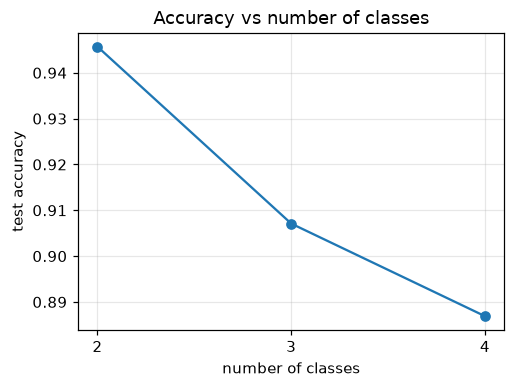

In [18]:
class_runs = {}
for k in range(2, len(ALL_CLASSES) + 1):
    _, h, _ = run(f'{k} classes', classes=ALL_CLASSES[:k])
    class_runs[f'{k} classes: {", ".join(ALL_CLASSES[:k])}'] = h
compare(class_runs, title='#classes:')
tab = summarize(class_runs); display(tab)

plt.figure(figsize=(5, 3.5))
plt.plot(range(2, len(ALL_CLASSES) + 1), tab['test_acc@best_val'], marker='o')
plt.xticks(range(2, len(ALL_CLASSES) + 1)); plt.xlabel("number of classes"); plt.ylabel("test accuracy")
plt.title("Accuracy vs number of classes"); plt.show()

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[boats vs cars] done in 198s | best epoch 10 | test acc @best-val 0.946


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[boats vs planes] done in 185s | best epoch 10 | test acc @best-val 0.900


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

...

[cars vs planes] done in 168s | best epoch 10 | test acc @best-val 0.935


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[cars vs trains] done in 188s | best epoch 10 | test acc @best-val 0.971


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[planes vs trains] done in 173s | best epoch 10 | test acc @best-val 0.961


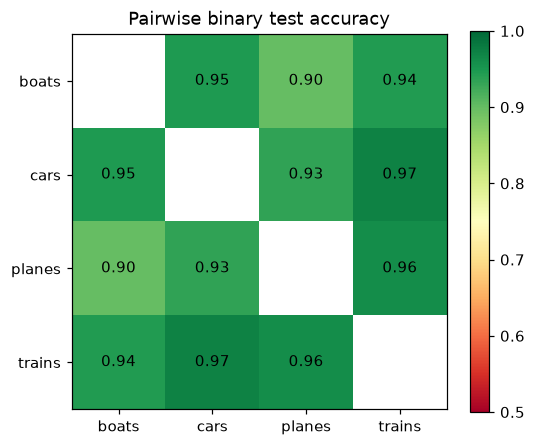

Hardest pairs:


,a,b,acc
2,boats,planes,0.900000
6,cars,planes,0.934783
3,boats,trains,0.944444


In [19]:
# (b) every pair of classes as its own binary problem
pair_acc = pd.DataFrame(np.nan, index=ALL_CLASSES, columns=ALL_CLASSES)
for a, b in itertools.combinations(ALL_CLASSES, 2):
    _, h, _ = run(f'{a} vs {b}', classes=[a, b])
    pair_acc.loc[a, b] = pair_acc.loc[b, a] = h['test_acc'][h['best_epoch'] - 1]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(pair_acc.values.astype(float), cmap='RdYlGn', vmin=0.5, vmax=1.0)
ax.set_xticks(range(len(ALL_CLASSES))); ax.set_xticklabels(ALL_CLASSES)
ax.set_yticks(range(len(ALL_CLASSES))); ax.set_yticklabels(ALL_CLASSES); ax.grid(False)
for i in range(len(ALL_CLASSES)):
    for j in range(len(ALL_CLASSES)):
        if i != j: ax.text(j, i, f"{pair_acc.values[i, j]:.2f}", ha='center', va='center')
plt.colorbar(im); ax.set_title("Pairwise binary test accuracy"); plt.show()

pairs = pair_acc.stack().reset_index(); pairs.columns = ['a', 'b', 'acc']
pairs = pairs[pairs.a < pairs.b].sort_values('acc')
print("Hardest pairs:"); display(pairs.head(3))

**Reading the results:** a binary problem between visually similar classes should score lowest. 

**(c) Can you find classes that are hard to learn?** Add a deliberately ambiguous class (e.g. `ships` next to `boats`, `buses` next to `trains`/`cars`) by downloading it into `train/` and `test/` the same way, then re-run from Section 2 and compare.

## 8. Q2: Depth, width, dropout, activation, and fine-tuning

### 8a. Backbone depth: ResNet18 vs 34 vs 50
Deeper backbones give richer features but are slower, and the head input size changes (512 -> 512 -> 2048).

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[resnet18] done in 255s | best epoch 9 | test acc @best-val 0.887
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /home/mids/m284932/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|████████████████████████████████████| 83.3M/83.3M [00:00<00:00, 288MB/s]
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:

[resnet34] done in 313s | best epoch 10 | test acc @best-val 0.899
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/mids/m284932/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|████████████████████████████████████| 97.8M/97.8M [00:00<00:00, 295MB/s]
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:

[resnet50] done in 704s | best epoch 10 | test acc @best-val 0.949


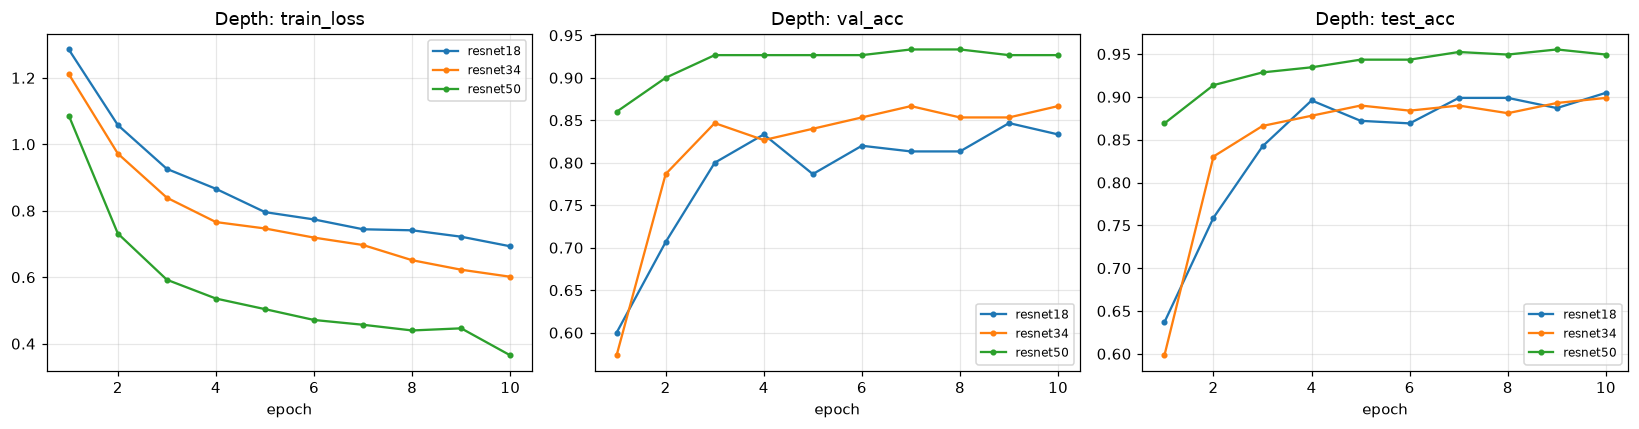

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
resnet18,2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,25.4992,254.9917
resnet34,2052,10,10,7,0.7835,0.8667,0.8988,0.8988,-0.1153,31.2757,312.7574
resnet50,8196,10,10,3,0.8835,0.9333,0.9494,0.9494,-0.0659,70.3806,703.8062


In [20]:
depth_runs = {}
for arch in ['resnet18', 'resnet34', 'resnet50']:
    _, h, _ = run(arch, arch=arch)
    depth_runs[arch] = h
compare(depth_runs, title='Depth:')
display(summarize(depth_runs))

### 8b. Head design: width, dropout, activation
`hidden=0` is the given single-linear head. Others add a hidden layer.

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[hidden=0] done in 265s | best epoch 9 | test acc @best-val 0.887


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[hidden=64] done in 268s | best epoch 9 | test acc @best-val 0.911


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[hidden=256] done in 266s | best epoch 7 | test acc @best-val 0.899


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[hidden=1024] done in 267s | best epoch 7 | test acc @best-val 0.902


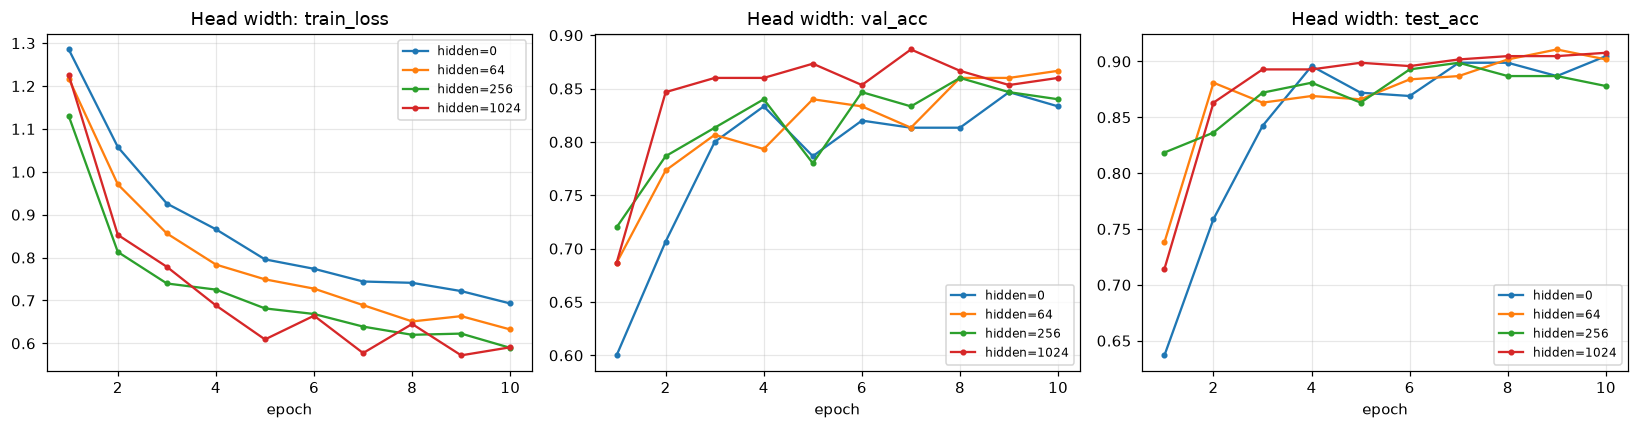

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
hidden=0,2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,26.4991,264.9907
hidden=64,33092,10,9,8,0.7576,0.8667,0.9018,0.9107,-0.1441,26.7769,267.7692
hidden=256,132356,10,7,8,0.7659,0.8600,0.8780,0.8988,-0.1121,26.5739,265.7396
hidden=1024,529412,10,7,7,0.7694,0.8867,0.9077,0.9018,-0.1383,26.7352,267.3522


In [21]:
head_runs = {}
for hidden in [0, 64, 256, 1024]:
    _, h, _ = run(f'hidden={hidden}', hidden=hidden)
    head_runs[f'hidden={hidden}'] = h
compare(head_runs, title='Head width:')
display(summarize(head_runs))

In [22]:
drop_runs = {}
for p in [0.0, 0.2, 0.5, 0.7]:
    _, h, _ = run(f'dropout={p}', hidden=256, dropout=p)
    drop_runs[f'dropout={p}'] = h
compare(drop_runs, metrics=('train_acc', 'test_acc', 'test_loss'), title='Dropout (hidden=256):')
display(summarize(drop_runs))

/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

[dropout=0.0] done in 267s | best epoch 7 | test acc @best-val 0.899


/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/mids/m284932/miniforge3/envs/transfer/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should 

KeyboardInterrupt: 

In [ ]:
act_runs = {}
for name, act in [('ReLU', nn.ReLU), ('LeakyReLU', nn.LeakyReLU), ('GELU', nn.GELU), ('Tanh', nn.Tanh), ('Sigmoid', nn.Sigmoid)]:
    _, h, _ = run(f'act={name}', hidden=256, act=act)
    act_runs[name] = h
compare(act_runs, title='Activation (hidden=256):')
display(summarize(act_runs))

### 8c. Fine-tuning more than the head
Unfreeze the last ResNet stage(s), with a smaller learning rate so the pretrained weights aren't wrecked. This goes beyond pure transfer learning but is a common next step.

In [ ]:
ft_runs = {}
_, ft_runs['head only (lr 1e-3)'], _ = run('head only')
_, ft_runs['+layer4 (lr 1e-4)'], _ = run('+layer4', lr=1e-4, unfreeze=('layer4',))
_, ft_runs['+layer3,4 (lr 1e-4)'], _ = run('+layer3,4', lr=1e-4, unfreeze=('layer3', 'layer4'))
compare(ft_runs, title='Fine-tuning:')
display(summarize(ft_runs))

## 9. Q3: Learning rate

In [ ]:
lr_runs = {}
for lr in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    _, h, _ = run(f'lr={lr:g}', lr=lr)
    lr_runs[f'lr={lr:g}'] = h
compare(lr_runs, title='LR:')
tab = summarize(lr_runs); display(tab)

plt.figure(figsize=(5.5, 3.5))
plt.semilogx([float(k.split('=')[1]) for k in lr_runs], tab['test_acc@best_val'], marker='o')
plt.xlabel("learning rate"); plt.ylabel("test accuracy"); plt.title("Accuracy vs learning rate"); plt.show()

Expect: very small LRs converge slowly (underfit within the epoch budget), 1e-3 is a good default for Adam on a linear head, and very large LRs make the loss bounce and can lower final accuracy.

## 10. Q4: Data augmentation, overfitting, and normalization
Compare no augmentation, flip only, the given augmentations, a heavier set, and the given set with ImageNet normalization (which the pretrained weights expect). Runs are longer (`AUG_EPOCHS`) so we can see when each one overfits. The **train-test accuracy gap** is the overfitting signal. (Train accuracy is measured on augmented batches, so heavy augmentation lowers it by design.)

In [ ]:
AUG_EPOCHS = 20
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

aug_sets = {
    'none': transforms.Compose([transforms.Resize((256, 256)), transforms.ToTensor()]),
    'flip only': transforms.Compose([transforms.Resize((256, 256)), transforms.RandomHorizontalFlip(), transforms.ToTensor()]),
    'given': random_transform,
    'heavier': transforms.Compose([
        transforms.RandomResizedCrop(256, scale=(0.3, 1.0)), transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(40), transforms.RandomPerspective(0.3, p=0.5),
        transforms.ColorJitter(0.4, 0.4, 0.4, 0.1), transforms.RandomGrayscale(0.1),
        transforms.GaussianBlur(5), transforms.ToTensor(), transforms.RandomErasing(p=0.5)]),
}
aug_runs = {}
for name, tf in aug_sets.items():
    _, aug_runs[name], _ = run(f'aug={name}', train_tf=tf, epochs=AUG_EPOCHS)

# given augmentations + ImageNet normalization (test transform must match)
tf_norm = transforms.Compose(random_transform.transforms + [norm])
te_norm = transforms.Compose(common_transform.transforms + [norm])
_, aug_runs['given + ImageNet norm'], _ = run('aug=given+norm', train_tf=tf_norm, test_tf=te_norm, epochs=AUG_EPOCHS)

compare(aug_runs, metrics=('train_acc', 'test_acc', 'test_loss'), title='Augmentation:')
display(summarize(aug_runs))

In [ ]:
# overfitting signal: train-test gap per epoch, and validation loss (when does it start rising?)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in aug_runs.items():
    ax[0].plot(np.array(h['train_acc']) - np.array(h['test_acc']), label=name)
    ax[1].plot(h['val_loss'], label=name)
ax[0].axhline(0, color='k', lw=0.8)
ax[0].set(title="Train acc - test acc (bigger = more overfit)", xlabel="epoch")
ax[1].set(title="Validation loss (rising = overfitting)", xlabel="epoch")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

print("Epoch of minimum validation loss (later = takes longer to overfit):")
print({k: h['best_epoch'] for k, h in aug_runs.items()})

## 11. Q5: Early stopping
`train_model(..., patience=N)` stops when validation loss hasn't improved for N epochs and restores the best weights. With a frozen backbone and linear head, overfitting is mild, so this demo uses **no augmentation and a bigger head** (easier to overfit), 40 max epochs.

In [ ]:
es_kw = dict(train_tf=aug_sets['none'], hidden=512, epochs=40)
m_full, h_full, _ = run('no early stopping', **es_kw)
m_es, h_es, L_es = run('early stopping (patience=5)', patience=5, **es_kw)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for h, lab, c in [(h_full, 'no early stopping', 'C0'), (h_es, 'patience=5', 'C1')]:
    ax[0].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label=lab, color=c, marker='o', ms=3)
    ax[1].plot(range(1, len(h['test_acc']) + 1), h['test_acc'], label=lab, color=c, marker='o', ms=3)
ax[0].axvline(h_es['best_epoch'], color='gray', ls='--', label=f"best epoch {h_es['best_epoch']}")
ax[0].set(title="Validation loss", xlabel='epoch'); ax[1].set(title="Test accuracy", xlabel='epoch')
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

print(f"No early stopping : {len(h_full['val_loss'])} epochs, {h_full['time']:.0f}s, final test acc {h_full['test_acc'][-1]:.4f}")
print(f"Early stopping    : {len(h_es['val_loss'])} epochs, {h_es['time']:.0f}s, "
      f"test acc with restored best weights {evaluate(m_es, L_es['test'])['acc']:.4f}")

In [ ]:
# sensitivity to patience
pat_runs = {}
for pat in [2, 5, 10]:
    _, pat_runs[f'patience={pat}'], _ = run(f'patience={pat}', patience=pat, **es_kw)
display(summarize(pat_runs)[['epochs_run', 'best_epoch', 'test_acc@best_val', 'total_sec']])

## 12. Extra: how much training data do we need?
Learning curve: train on 10%, 25%, 50%, 100% of the training split. This shows whether scraping more images is worth it.

In [ ]:
frac_runs = {}
for f in [0.1, 0.25, 0.5, 1.0]:
    _, frac_runs[f], _ = run(f'{int(f*100)}% data', train_frac=f)
fr = summarize(frac_runs)
fr.index = [f"{int(f*100)}%" for f in frac_runs]
display(fr[['val_acc(best)', 'test_acc@best_val', 'best_epoch', 'total_sec']])

plt.figure(figsize=(5.5, 3.5))
plt.plot([f * 100 for f in frac_runs], fr['test_acc@best_val'], marker='o', label='test')
plt.plot([f * 100 for f in frac_runs], fr['val_acc(best)'], marker='s', label='val')
plt.xlabel("% of training data"); plt.ylabel("accuracy"); plt.title("Learning curve"); plt.legend(); plt.show()

In [ ]:
# every experiment on one chart (test accuracy @ best val epoch)
all_runs = {}
for grp in [depth_runs, head_runs, drop_runs, act_runs, ft_runs, lr_runs, aug_runs]:
    all_runs.update(grp)
s = summarize(all_runs)['test_acc@best_val'].sort_values()
plt.figure(figsize=(7, 0.28 * len(s) + 1))
plt.barh(s.index, s.values, color='C0'); plt.xlim(max(0, s.min() - 0.05), 1.0)
plt.xlabel("test accuracy"); plt.title("All experiments"); plt.show()

## 13. Final model
Edit `BEST` based on what worked in Sections 7-12, then train with early stopping and evaluate on the test set.

In [ ]:
BEST = dict(arch='resnet18', hidden=256, dropout=0.2, act=nn.ReLU, unfreeze=(), lr=1e-3,
            train_tf=None, test_tf=None)   # None -> given augmentations / plain resize

final_model, final_h, final_L = run('final', epochs=40, patience=6, **BEST)
plot_history(final_h, 'Final')
r_final = report(final_model, final_L, 'Final')
show_mistakes(r_final, final_L)
print(f"FINAL TEST ACCURACY: {r_final['acc'] * 100:.2f}%")
torch.save(final_model.state_dict(), 'vehicle_classifier.pt')

### Write-up template
- **Dataset:** classes, images per class, issues found (duplicates, mislabeled, size).
- **Baseline:** test accuracy, which classes got confused, what the t-SNE showed.
- **More classes:** accuracy trend, hardest pair(s) from the pairwise heatmap.
- **Depth / head:** effect on convergence speed, ultimate accuracy, and time per epoch.
- **Learning rate:** best range and failure modes at each end.
- **Augmentation:** which settings overfit sooner, effect of normalization.
- **Early stopping:** epochs saved and accuracy impact.
- **Final model:** configuration and test accuracy.